DATA 78000, Data Clustering assignment.

**Research question.** Do House members sort into recognizable "types" based on how effective they are as lawmakers,
and do those types line up with the backgrounds they bring to Congress?

**Two datasets, joined on the BioGuide ID (Wikidata property P1157):**

| Source | What it gives me | Used for |
|---|---|---|
| Center for Effective Lawmaking (CEL), House file, 93rd–118th Congress | Legislative Effectiveness Scores, DW-NOMINATE ideology, birth year, year first elected, prior state legislative service | K-Means (numerical) |
| Wikidata, queried with SPARQL (`wikidata_query.sql`) | Occupation (P106), military branch (P241), academic degree (P512) | K-Modes (categorical) |




In [1]:
# Install packages (only needed in Colab or a fresh environment)
%pip install -q pandas numpy scikit-learn kmodes matplotlib requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kmodes.kmodes import KModes
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [ ]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

FIRST_CONGRESS = 107       # 107th Congress started in 2001, so this keeps 2001-2024
REFRESH_WIKIDATA = False   # True = re-run the SPARQL query instead of using the saved CSV
K_MEANS_K = 3              # chosen from the elbow plot below
K_MODES_K = 3              # chosen from the cost plot below


CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
INK = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#bcbbb5",
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

## 1. CEL House data 

Average of each member's
scores across every Congress they served between 2001 and 2024.

Numerical features for K-Means:

1. **Effectiveness relative to expectations** (`benchratio1`). This is CEL's Legislative Effectiveness Score divided by
   the score CEL *expects* for someone in that member's position (majority or minority, seniority, committee chair).
   A value of 1.0 means "did what was expected." 
2. **Ideological extremity** (`|dwnom1|`). The absolute value of the first DW-NOMINATE dimension. Near 0 means close to
   the center. Higher means further left or right. I use this as a stand-in for bipartisanship.
3. **Age at entry**. Year first elected to the House minus birth year.

In [3]:
# Read the CEL House file (Stata format) and keep only the 2001-2024 Congresses
cel = pd.read_stata(DATA_DIR / "CELHouse93to118Reduced.dta")
cel = cel[cel["congress"] >= FIRST_CONGRESS].copy()
print(f"Member-Congress rows kept: {len(cel):,}")

# Ideological extremity: distance from 0 on the left-right scale, ignoring direction
cel["extremity"] = cel["dwnom1"].abs()

# Collapse to one row per member. Means for scores, min for first election, max for yes/no flags.
members = (
    cel.groupby("bioguide_id")
    .agg(
        name=("thomas_name", "first"),
        party_dem=("dem", "last"),
        congresses_served=("congress", "size"),
        les_ratio=("benchratio1", "mean"),
        les_raw=("lesclassic", "mean"),
        extremity=("extremity", "mean"),
        born=("born", "first"),
        first_elected=("elected", "min"),
        state_leg=("state_leg", "max"),
        majority_share=("majority", "mean"),
    )
    .reset_index()
)
members["age_at_entry"] = members["first_elected"] - members["born"]
members["party"] = np.where(members["party_dem"] == 1, "Democrat", "Republican/other")
print(f"Unique House members: {len(members):,}")
members.head()

Member-Congress rows kept: 5,375
Unique House members: 1,245


,bioguide_id,name,party_dem,congresses_served,les_ratio,les_raw,extremity,born,first_elected,state_leg,majority_share,age_at_entry,party
0,A000014,"Abercrombie, Neil",1,5,0.646504,0.533064,0.432000,1938.0,1990,1.0,0.400000,52.0,Democrat
1,A000022,"Ackerman, Gary",1,6,0.313168,0.316877,0.429000,1942.0,1983,1.0,0.333333,41.0,Democrat
2,A000055,"Aderholt, Robert",0,12,0.475358,0.568136,0.373167,1965.0,1996,0.0,0.666667,31.0,Republican/other
3,A000148,"Auchincloss, Jake",1,2,0.409122,0.306263,0.305500,1988.0,2020,0.0,0.500000,32.0,Democrat
4,A000210,"Andrews, Robert",1,7,1.693849,0.954036,0.297000,1957.0,1990,0.0,0.285714,33.0,Democrat


## 2. Wikidata

`wikidata_query.sql` returns one row per person with a BioGuide ID. 

In [4]:
import requests

if REFRESH_WIKIDATA:
    # Send the saved SPARQL query to the Wikidata Query Service and save the CSV it returns
    query = Path("wikidata_query.sql").read_text(encoding="utf-8")
    response = requests.get(
        "https://query.wikidata.org/sparql",
        params={"query": query},
        headers={"Accept": "text/csv", "User-Agent": "CUNY-DATA78000-assignment/1.0"},
        timeout=120,
    )
    response.raise_for_status()
    (DATA_DIR / "wikidata_house_backgrounds.csv").write_bytes(response.content)

wiki = pd.read_csv(DATA_DIR / "wikidata_house_backgrounds.csv")
print(f"People with a BioGuide ID returned by Wikidata: {len(wiki):,}")

# Left join keeps every CEL member, even if Wikidata had nothing for them
df = members.merge(wiki, left_on="bioguide_id", right_on="bioguideId", how="left")
print(f"CEL members matched to a Wikidata item: {df['bioguideId'].notna().sum():,} of {len(df):,}")

People with a BioGuide ID returned by Wikidata: 2,465


CEL members matched to a Wikidata item: 1,245 of 1,245


### Data Check

In [5]:
coverage = pd.DataFrame({
    "Wikidata property": ["Occupation (P106)", "Academic degree (P512)", "Military branch (P241)"],
    "Members with a value": [df[c].notna().sum() for c in ["occupations", "degrees", "militaryBranches"]],
})
coverage["Percent of members"] = (100 * coverage["Members with a value"] / len(df)).round(1)
coverage

,Wikidata property,Members with a value,Percent of members
0,Occupation (P106),1019,81.8
1,Academic degree (P512),28,2.2
2,Military branch (P241),275,22.1


## 3. K-Means on the numerical features

### Data prep

In [6]:
KMEANS_FEATURES = ["les_ratio", "extremity", "age_at_entry"]

# Drop members missing any of the three features (mostly people with no ideology score yet)
km_df = df.dropna(subset=KMEANS_FEATURES).copy()
print(f"Members with all three numerical features: {len(km_df):,} (dropped {len(df) - len(km_df)})")
print(km_df[KMEANS_FEATURES].describe().round(2))

# Standardize to z-scores so every feature has the same weight in the distance calculation
scaler = StandardScaler()
X = scaler.fit_transform(km_df[KMEANS_FEATURES])

Members with all three numerical features: 1,234 (dropped 11)
       les_ratio  extremity  age_at_entry
count    1234.00    1234.00       1234.00
mean        1.06       0.41         47.26
std         0.79       0.16          9.25
min         0.00       0.01         25.00
25%         0.53       0.30         40.00
50%         0.88       0.40         47.00
75%         1.42       0.52         54.00
max         7.38       0.94         77.00


### Choose k with the Elbow Method

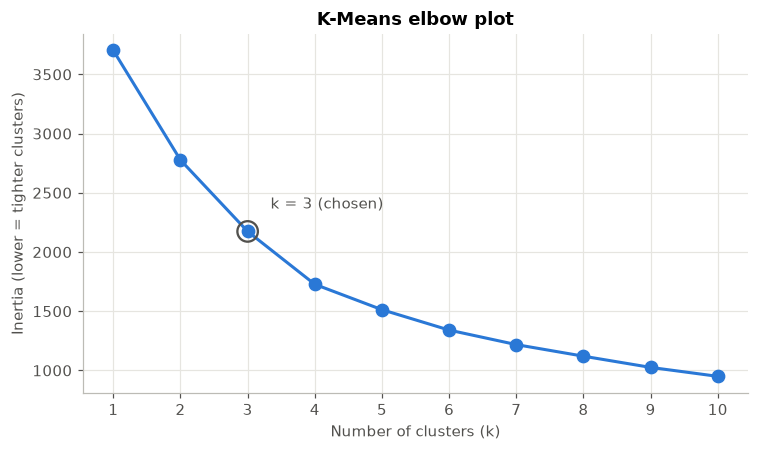

k=1: inertia=3,702
k=2: inertia=2,777
k=3: inertia=2,174
k=4: inertia=1,727
k=5: inertia=1,513
k=6: inertia=1,341
k=7: inertia=1,218
k=8: inertia=1,120
k=9: inertia=1,026
k=10: inertia=950


In [7]:
# Fit K-Means for k = 1..10 and record inertia (within-cluster sum of squares)
k_range = range(1, 11)
inertia = []
for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(k_range, inertia, marker="o", color=CLUSTER_COLORS[0], linewidth=2, markersize=8)
ax.scatter([K_MEANS_K], [inertia[K_MEANS_K - 1]], s=180, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=3)
ax.annotate(f"k = {K_MEANS_K} (chosen)", (K_MEANS_K, inertia[K_MEANS_K - 1]), xytext=(15, 15),
            textcoords="offset points", color=INK)
ax.set_title("K-Means elbow plot")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia (lower = tighter clusters)")
ax.set_xticks(list(k_range))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_kmeans_elbow.png", dpi=200)
plt.show()

for k, val in zip(k_range, inertia):
    print(f"k={k}: inertia={val:,.0f}")

The curve bends gently around k = 3 and 4 rather than at one sharp elbow. I pick **k = 3** because each extra cluster
after that only peels off a smaller group, and three groups are easier to interpret and to plot.

In [8]:
# Fit the final K-Means model
final_km = KMeans(n_clusters=K_MEANS_K, random_state=42, n_init=10)
km_df["kmeans_cluster"] = final_km.fit_predict(X)

# Give each cluster a plain-language name based on its average profile:
#   the highest effectiveness ratio -> "Overachievers"
#   of the other two, the younger average entry age -> "Early starters", the older -> "Late starters"
profile = km_df.groupby("kmeans_cluster")[KMEANS_FEATURES].mean()
over = profile["les_ratio"].idxmax()
rest = profile.drop(index=over).sort_values("age_at_entry")
names = {over: "Overachievers", rest.index[0]: "Early starters", rest.index[1]: "Late starters"}
km_df["kmeans_type"] = km_df["kmeans_cluster"].map(names)
KM_ORDER = ["Overachievers", "Early starters", "Late starters"]

# Cluster profile table: averages of the clustering features plus a few context columns
summary = (
    km_df.groupby("kmeans_type")
    .agg(
        members=("bioguide_id", "size"),
        les_ratio=("les_ratio", "mean"),
        raw_les=("les_raw", "mean"),
        extremity=("extremity", "mean"),
        age_at_entry=("age_at_entry", "mean"),
        pct_democrat=("party_dem", "mean"),
        pct_majority=("majority_share", "mean"),
        congresses_served=("congresses_served", "mean"),
    )
    .loc[KM_ORDER]
)
summary["pct_democrat"] *= 100
summary["pct_majority"] *= 100
summary.round(2)

,members,les_ratio,raw_les,extremity,age_at_entry,pct_democrat,pct_majority,congresses_served
kmeans_type,,,,,,,,
Overachievers,207,2.30,1.76,0.32,49.27,55.07,57.830002,3.99
Early starters,533,0.84,0.88,0.36,40.09,52.53,55.439999,4.40
Late starters,494,0.78,0.74,0.51,54.14,34.01,59.889999,4.39


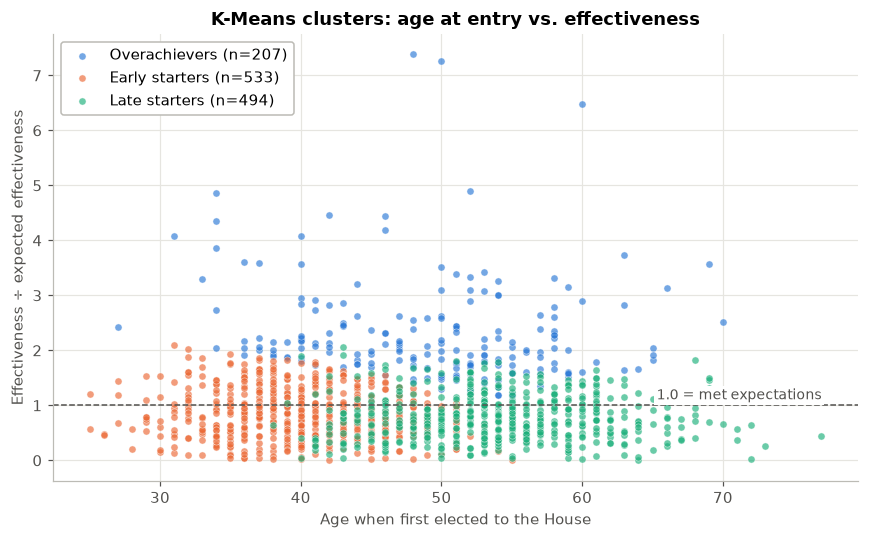

In [9]:
# Scatter plot: age at entry vs. effectiveness ratio, colored by cluster.
# (Extremity is the third feature. It shows up in the bar chart below.)
fig, ax = plt.subplots(figsize=(8, 5))
for color, name in zip(CLUSTER_COLORS, KM_ORDER):
    pts = km_df[km_df["kmeans_type"] == name]
    ax.scatter(pts["age_at_entry"], pts["les_ratio"], s=22, alpha=0.65, color=color,
               edgecolors="white", linewidths=0.4, label=f"{name} (n={len(pts)})")
ax.axhline(1.0, color=INK, linestyle="--", linewidth=1)
ax.text(km_df["age_at_entry"].max(), 1.05, "1.0 = met expectations", ha="right", va="bottom", color=INK, fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.set_title("K-Means clusters: age at entry vs. effectiveness")
ax.set_xlabel("Age when first elected to the House")
ax.set_ylabel("Effectiveness ÷ expected effectiveness")
ax.legend(frameon=True, facecolor="white", edgecolor="#bcbbb5", framealpha=1, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_kmeans_scatter.png", dpi=200)
plt.show()

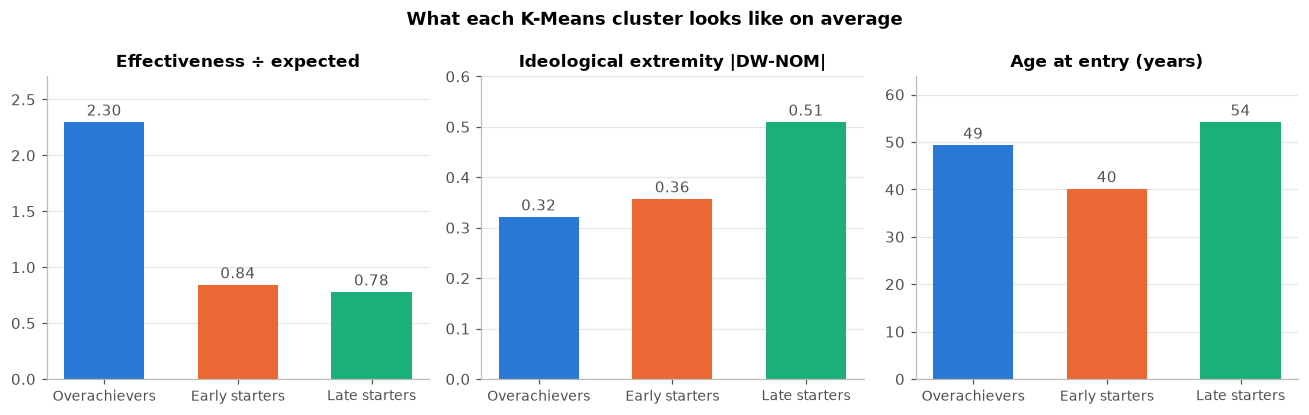

In [10]:
# Small bar charts: the average of each clustering feature, one panel per feature
labels = {
    "les_ratio": "Effectiveness ÷ expected",
    "extremity": "Ideological extremity |DW-NOM|",
    "age_at_entry": "Age at entry (years)",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, feat in zip(axes, KMEANS_FEATURES):
    vals = summary[feat]
    bars = ax.bar(KM_ORDER, vals, color=CLUSTER_COLORS, width=0.6)
    ax.bar_label(bars, fmt="%.2f" if feat != "age_at_entry" else "%.0f", color=INK, padding=2)
    ax.set_title(labels[feat], fontsize=11)
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, vals.max() * 1.18)
fig.suptitle("What each K-Means cluster looks like on average", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_kmeans_profiles.png", dpi=200)
plt.show()

In [11]:
# A few example members from each cluster (highest effectiveness ratio first), to sanity-check the groups
for name in KM_ORDER:
    top = km_df[km_df["kmeans_type"] == name].sort_values("les_ratio", ascending=False).head(6)
    print(f"{name}: " + "; ".join(top["name"].astype(str)))

Overachievers: Udall, Mark; Udall, Tom; Carson, Brad; Ballance, Frank; Katko, John; Neguse, Joe
Early starters: Evans, Lane; Meijer, Peter; Larsen, Rick; Torres, Ritchie; Polis, Jared; Hurd, William
Late starters: Garrett, Scott; Pfluger, August; Steube, Greg; Watson, Diane; Bishop, Rob; Lummis, Cynthia


## 4. K-Modes 

Wikidata gives 150+ distinct occupation labels and often several per person, so I collapse them into
broad groups with a simple keyword rule.

*Assumption :* when someone has more than one occupation, the *first group in my list that matches*
wins (Law, then Business, and so on). 

In [12]:
# Keyword rules for collapsing Wikidata occupation labels into broad groups (checked in this order)
OCCUPATION_GROUPS = [
    ("Law", ["lawyer", "jurist", "judge", "prosecutor", "attorney", "barrister", "solicitor", "public defender"]),
    ("Business", ["business", "entrepreneur", "executive", "real estate", "banker", "manager", "accountant",
                  "financ", "investor", "insurance", "farmer", "rancher", "restaurateur", "consultant",
                  "economist", "stockbroker", "car dealer", "marketer", "founder"]),
    ("Military / police", ["military", "soldier", "officer", "police", "sheriff", "pilot", "firefighter"]),
    ("Education", ["teacher", "professor", "educator", "academic", "school", "lecturer", "university"]),
    ("Medicine / science", ["physician", "nurse", "surgeon", "dentist", "doctor", "pharmacist", "scientist",
                            "engineer", "veterinarian", "psycholog", "chemist", "physicist", "optometrist",
                            "pediatric", "agronom"]),
    ("Media / arts / sports", ["journalist", "writer", "radio", "television", "actor", "author", "broadcaster",
                               "presenter", "player", "athlete", "musician", "news", "editor", "columnist",
                               "singer", "film", "coach", "wrestler", "boxer", "artist", "speaker"]),
    ("Public service / advocacy", ["civil servant", "congressional staff", "diplomat", "lobbyist", "peace corps",
                                   "social worker", "activist", "advocate", "trade unionist", "staff"]),
]


def occupation_group(cell):
    """Map a '|'-separated list of Wikidata occupations to one broad group."""
    if pd.isna(cell):
        return "Not listed"
    jobs = cell.lower().split("|")
    for group, keywords in OCCUPATION_GROUPS:
        if any(kw in job for job in jobs for kw in keywords):
            return group
    return "Other"


def military_group(cell):
    """Map Wikidata military branch labels to one main branch (Reserve and Guard units fold into their branch)."""
    if pd.isna(cell):
        return "None listed"
    text = cell.lower()
    for branch, kw in [("Army", "army"), ("Navy", "navy"), ("Air Force", "air"), ("Marine Corps", "marine")]:
        if kw in text:
            return branch
    return "Other branch"


df["occupation"] = df["occupations"].map(occupation_group)
df["military"] = df["militaryBranches"].map(military_group)
df["state_legislature"] = np.where(df["state_leg"] == 1, "Yes", "No")

KMODES_FEATURES = ["occupation", "military", "state_legislature"]
for col in KMODES_FEATURES:
    print(df[col].value_counts(), "\n")

occupation
Law                          397
Business                     343
Not listed                   226
Education                     94
Military / police             60
Media / arts / sports         36
Medicine / science            35
Public service / advocacy     30
Other                         24
Name: count, dtype: int64 

military
None listed     970
Army            139
Air Force        53
Navy             52
Marine Corps     23
Other branch      8
Name: count, dtype: int64 

state_legislature
No     666
Yes    579
Name: count, dtype: int64 



### Choose k with the cost curve

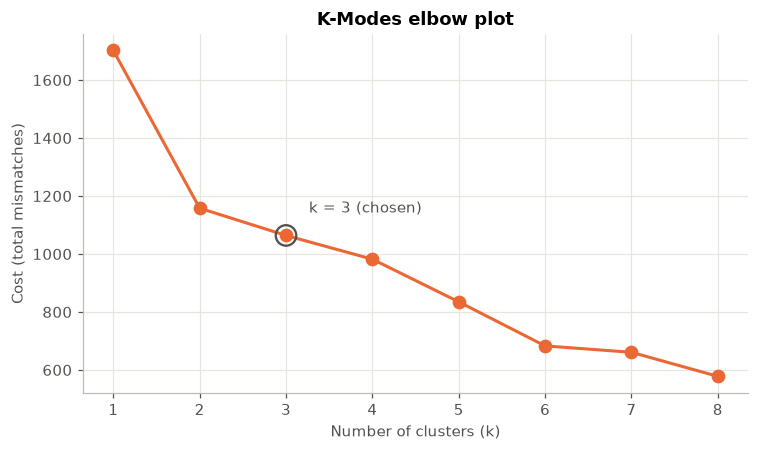

k=1: cost=1,702
k=2: cost=1,158
k=3: cost=1,064
k=4: cost=982
k=5: cost=835
k=6: cost=683
k=7: cost=661
k=8: cost=578


In [13]:
X_cat = df[KMODES_FEATURES]

# Fit K-Modes for k = 1..8 and record cost (total number of category mismatches)
k_range_modes = range(1, 9)
cost = []
for k in k_range_modes:
    model = KModes(n_clusters=k, init="Cao", n_init=5, random_state=42)
    model.fit(X_cat)
    cost.append(model.cost_)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(k_range_modes, cost, marker="o", color=CLUSTER_COLORS[1], linewidth=2, markersize=8)
ax.scatter([K_MODES_K], [cost[K_MODES_K - 1]], s=180, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=3)
ax.annotate(f"k = {K_MODES_K} (chosen)", (K_MODES_K, cost[K_MODES_K - 1]), xytext=(15, 15),
            textcoords="offset points", color=INK)
ax.set_title("K-Modes elbow plot")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Cost (total mismatches)")
ax.set_xticks(list(k_range_modes))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_kmodes_elbow.png", dpi=200)
plt.show()

for k, val in zip(k_range_modes, cost):
    print(f"k={k}: cost={val:,.0f}")

The sharpest bend is at **k = 2**, which splits members mostly on prior state legislative service. I go one step further
to **k = 3** because the third cluster pulls out the Army veterans, the only group with a clearly different profile.

In [ ]:
# Fit the final K-Modes model
final_kmodes = KModes(n_clusters=K_MODES_K, init="Cao", n_init=5, random_state=42)
df["kmodes_cluster"] = final_kmodes.fit_predict(X_cat)

# Each cluster's "mode" is its most common value on every feature. I use it as the cluster's name.
modes = pd.DataFrame(final_kmodes.cluster_centroids_, columns=KMODES_FEATURES)
modes["label"] = (modes["occupation"] + ", " + modes["military"].replace({"None listed": "no service listed"})
                  + ", state leg: " + modes["state_legislature"])
df["kmodes_type"] = df["kmodes_cluster"].map(modes["label"])
modes["members"] = df["kmodes_cluster"].value_counts().sort_index()

for col in KMODES_FEATURES:
    modes[f"% match {col}"] = [
        round(100 * (df.loc[df["kmodes_cluster"] == c, col] == modes.loc[c, col]).mean())
        for c in modes.index
    ]
modes

,occupation,military,state_legislature,label,members,% match occupation,% match military,% match state_legislature
0,Law,None listed,No,"Law, no service listed, state leg: No",781,51,85,76
1,Business,None listed,Yes,"Business, no service listed, state leg: Yes",391,39,77,100
2,Business,Army,No,"Business, Army, state leg: No",73,59,70,100


#### Do the background clusters (K-Modes) differ in effectiveness? And how do they overlap with the K-Means types?

In [ ]:

both = df.merge(km_df[["bioguide_id", "kmeans_type"]], on="bioguide_id", how="left")

by_background = (
    both.groupby("kmodes_type")
    .agg(members=("bioguide_id", "size"),
         avg_les_ratio=("les_ratio", "mean"),
         pct_overachievers=("kmeans_type", lambda s: 100 * (s == "Overachievers").mean()),
         pct_democrat=("party_dem", lambda s: 100 * s.mean()))
    .sort_values("members", ascending=False)
    .round(2)
)
by_background

,members,avg_les_ratio,pct_overachievers,pct_democrat
kmodes_type,,,,
"Law, no service listed, state leg: No",781,1.09,17.16,50.06
"Business, no service listed, state leg: Yes",391,1.08,17.39,41.94
"Business, Army, state leg: No",73,0.89,6.85,20.55


In [16]:
# Cross-tab: each row (background cluster) sums to 100%
crosstab = pd.crosstab(both["kmodes_type"], both["kmeans_type"], normalize="index")[KM_ORDER] * 100
crosstab.round(1)

kmeans_type,Overachievers,Early starters,Late starters
kmodes_type,,,
"Business, Army, state leg: No",6.8,32.9,60.3
"Business, no service listed, state leg: Yes",17.5,36.8,45.8
"Law, no service listed, state leg: No",17.4,47.4,35.2


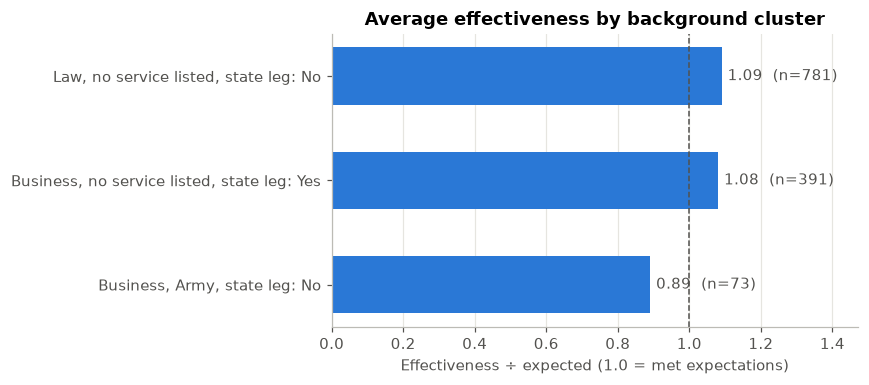

In [17]:
# Bar chart: average effectiveness ratio for each background cluster
order = by_background.sort_values("avg_les_ratio").index
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(order, by_background.loc[order, "avg_les_ratio"], color=CLUSTER_COLORS[0], height=0.55)
ax.bar_label(bars, labels=[f"{v:.2f}  (n={n})" for v, n in zip(by_background.loc[order, "avg_les_ratio"],
                                                              by_background.loc[order, "members"])],
             color=INK, padding=4)
ax.axvline(1.0, color=INK, linestyle="--", linewidth=1)
ax.set_xlim(0, by_background["avg_les_ratio"].max() * 1.35)
ax.set_title("Average effectiveness by background cluster")
ax.set_xlabel("Effectiveness ÷ expected (1.0 = met expectations)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_background_vs_effectiveness.png", dpi=200)
plt.show()

In [ ]:
out_cols = ["bioguide_id", "name", "party", "les_ratio", "les_raw", "extremity", "age_at_entry",
            "occupation", "military", "state_legislature", "kmeans_type", "kmodes_type"]
both[out_cols].to_csv(DATA_DIR / "members_with_clusters.csv", index=False)
summary.round(3).to_csv(DATA_DIR / "kmeans_cluster_summary.csv")
print("Saved data/members_with_clusters.csv and data/kmeans_cluster_summary.csv")

Saved data/members_with_clusters.csv and data/kmeans_cluster_summary.csv
